In [93]:
!pip install seaborn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [94]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

DATA_PATH = '../data/ready_to_use'

patients = pd.read_csv(f'{DATA_PATH}/patients_cleaned.csv')

## Explore

In [95]:
patients.head()

,patient_id,sex_at_birth,race_ethnicity_group,preferred_language,interpreter_needed_flag,zip_area_id,payer_primary_id,pcp_provider_id,chronic_condition_count,sdoh_risk_score
0,RBP000001,Female,Black non-Hispanic,Spanish,1,ZA003,PAY04,RBPV0019,2,45.2
1,RBP000002,Male,Hispanic/Latino,Spanish,1,ZA028,PAY01,RBPV0027,0,41.7
2,RBP000003,Female,White non-Hispanic,English,0,ZA015,PAY01,RBPV0022,4,57.1
3,RBP000004,Male,Hispanic/Latino,English,0,ZA008,PAY03,RBPV0005,2,33.7
4,RBP000005,Male,White non-Hispanic,English,0,ZA007,PAY01,RBPV0001,3,38.4


In [96]:
patients.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               12000 non-null  str    
 1   sex_at_birth             12000 non-null  str    
 2   race_ethnicity_group     12000 non-null  str    
 3   preferred_language       12000 non-null  str    
 4   interpreter_needed_flag  12000 non-null  int64  
 5   zip_area_id              12000 non-null  str    
 6   payer_primary_id         12000 non-null  str    
 7   pcp_provider_id          12000 non-null  str    
 8   chronic_condition_count  12000 non-null  int64  
 9   sdoh_risk_score          12000 non-null  float64
dtypes: float64(1), int64(2), str(7)
memory usage: 937.6 KB


In [97]:
patients.describe()

,interpreter_needed_flag,chronic_condition_count,sdoh_risk_score
count,12000.000000,12000.000000,12000.000000
mean,0.126417,1.686083,49.034075
std,0.332332,1.503239,15.236043
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,38.400000
50%,0.000000,1.000000,48.900000
75%,0.000000,3.000000,59.400000
max,1.000000,8.000000,100.000000


In [98]:
patients['pcp_provider_id'].unique()

<StringArray>
['RBPV0019', 'RBPV0027', 'RBPV0022', 'RBPV0005', 'RBPV0001', 'RBPV0013',
 'RBPV0021', 'RBPV0029', 'RBPV0026', 'RBPV0031', 'RBPV0003', 'RBPV0010',
 'RBPV0004', 'RBPV0009', 'RBPV0035', 'RBPV0024', 'RBPV0023', 'RBPV0036',
 'RBPV0017', 'RBPV0007', 'RBPV0028', 'RBPV0018', 'RBPV0014', 'RBPV0034',
 'RBPV0011', 'RBPV0032', 'RBPV0002', 'RBPV0015', 'RBPV0025', 'RBPV0033',
 'RBPV0016', 'RBPV0008', 'RBPV0020', 'RBPV0006', 'RBPV0030', 'RBPV0012']
Length: 36, dtype: str

In [99]:
patients['payer_primary_id'].unique()

<StringArray>
['PAY04', 'PAY01', 'PAY03', 'PAY05', 'PAY02', 'PAY07', 'PAY06', 'PAY08']
Length: 8, dtype: str

In [100]:
patients['interpreter_needed_flag'].unique()

array([1, 0])

In [101]:
patients['chronic_condition_count'].unique()

array([2, 0, 4, 3, 1, 5, 6, 7, 8])

In [102]:
patients['zip_area_id'].unique()

<StringArray>
['ZA003', 'ZA028', 'ZA015', 'ZA008', 'ZA007', 'ZA009', 'ZA014', 'ZA031',
 'ZA048', 'ZA012', 'ZA022', 'ZA027', 'ZA002', 'ZA023', 'ZA001', 'ZA041',
 'ZA058', 'ZA013', 'ZA036', 'ZA059', 'ZA005', 'ZA006', 'ZA016', 'ZA019',
 'ZA047', 'ZA010', 'ZA057', 'ZA046', 'ZA025', 'ZA055', 'ZA042', 'ZA020',
 'ZA032', 'ZA052', 'ZA053', 'ZA039', 'ZA045', 'ZA021', 'ZA038', 'ZA026',
 'ZA056', 'ZA011', 'ZA034', 'ZA024', 'ZA035', 'ZA043', 'ZA030', 'ZA040',
 'ZA049', 'ZA033', 'ZA029', 'ZA060', 'ZA051', 'ZA004', 'ZA044', 'ZA018',
 'ZA054', 'ZA017', 'ZA050', 'ZA037']
Length: 60, dtype: str

In [103]:
patients['preferred_language'].unique()

<StringArray>
['Spanish', 'English', 'Arabic', 'Mandarin', 'Not recorded', 'Nepali']
Length: 6, dtype: str

In [104]:
patients[(patients['preferred_language'] != 'English') & (patients['interpreter_needed_flag'] == 0)]

,patient_id,sex_at_birth,race_ethnicity_group,preferred_language,interpreter_needed_flag,zip_area_id,payer_primary_id,pcp_provider_id,chronic_condition_count,sdoh_risk_score
19,RBP000020,Female,Not recorded,Arabic,0,ZA014,PAY01,RBPV0035,0,43.1
42,RBP000043,Female,Asian,Not recorded,0,ZA042,PAY01,RBPV0009,2,41.4
69,RBP000070,Female,Hispanic/Latino,Spanish,0,ZA009,PAY05,RBPV0031,2,52.7
79,RBP000080,Female,White non-Hispanic,Not recorded,0,ZA038,PAY05,RBPV0001,3,95.0
99,RBP000100,Male,White non-Hispanic,Mandarin,0,ZA024,PAY03,RBPV0029,3,59.9
...,...,...,...,...,...,...,...,...,...,...
11895,RBP011896,Female,Not recorded,Not recorded,0,ZA005,PAY05,RBPV0031,0,36.0
11904,RBP011905,Female,White non-Hispanic,Mandarin,0,ZA011,PAY05,RBPV0013,1,36.7
11909,RBP011910,Female,White non-Hispanic,Not recorded,0,ZA028,PAY01,RBPV0036,0,51.0
11950,RBP011951,Male,Hispanic/Latino,Spanish,0,ZA030,PAY02,RBPV0002,0,69.7


In [105]:
patients['sex_at_birth'].unique()

<StringArray>
['Female', 'Male', 'Not recorded', 'Intersex']
Length: 4, dtype: str

In [106]:
patients['race_ethnicity_group'].unique()

<StringArray>
['Black non-Hispanic',    'Hispanic/Latino', 'White non-Hispanic',
  'Multiracial/Other',       'Not recorded',              'Asian']
Length: 6, dtype: str

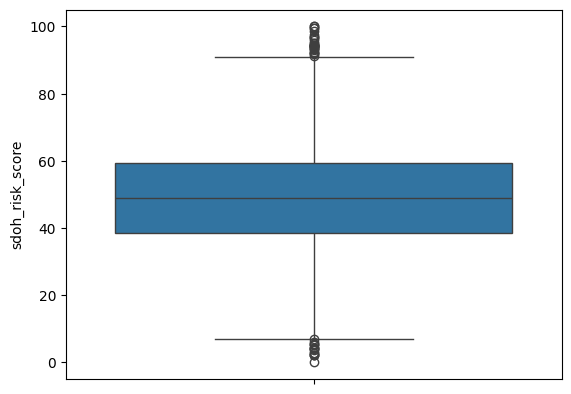

In [107]:
sns.boxplot(patients['sdoh_risk_score'])
plt.show()

In [108]:
Q1 = patients['sdoh_risk_score'].quantile(0.25)
Q3 = patients['sdoh_risk_score'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

print(f"sdoh_risk_score lower bound: {lower_bound}, upper bound: {upper_bound}")
print(f"values < lower = {patients['sdoh_risk_score'][patients['sdoh_risk_score'] < lower_bound].count()}")
print(f"values > upper = {patients['sdoh_risk_score'][patients['sdoh_risk_score'] > upper_bound].count()}")

sdoh_risk_score lower bound: 6.899999999999999, upper bound: 90.9
values < lower = 16
values > upper = 29


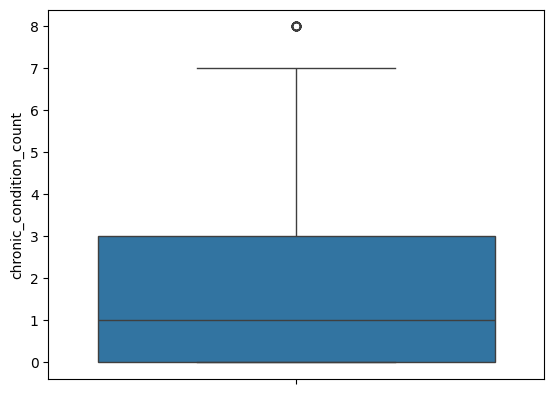

In [110]:
sns.boxplot(patients['chronic_condition_count'])
plt.show()

In [111]:
Q1 = patients['chronic_condition_count'].quantile(0.25)
Q3 = patients['chronic_condition_count'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

print(f"chronic_condition_count lower bound: {lower_bound}, upper bound: {upper_bound}")
print(f"values < lower = {patients['chronic_condition_count'][patients['chronic_condition_count'] < lower_bound].count()}")
print(f"values > upper = {patients['chronic_condition_count'][patients['chronic_condition_count'] > upper_bound].count()}")

chronic_condition_count lower bound: 0, upper bound: 7.5
values < lower = 0
values > upper = 25


In [109]:
patients['chronic_condition_count'][patients['chronic_condition_count'] == 8].count()

np.int64(25)